In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [3]:

from pathlib import Path
import pandas as pd

INPUT_ROOT = Path("/kaggle/input")

print("=" * 70)
print("UPLOADED FILES")
print("=" * 70)

for path in sorted(INPUT_ROOT.rglob("*")):
    if path.is_file():
        print(f"{path}  ({path.stat().st_size / (1024**2):.2f} MB)")

print("\n" + "=" * 70)
print("DATASET SPLIT CSV INSPECTION")
print("=" * 70)

csv_files = list(INPUT_ROOT.rglob("CASIA_Thousand_data_split.csv"))

if not csv_files:
    print("Split CSV not found. Check whether ocular-mia-inputs is attached.")
else:
    split_path = csv_files[0]
    df = pd.read_csv(split_path)

    print("CSV path:", split_path)
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    print(df.head().to_string(index=False))

    print("\nData types:")
    print(df.dtypes.to_string())

    for col in df.columns:
        if any(word in col.lower() for word in
               ["split", "identity", "subject", "label", "path"]):
            print(f"\nUnique values/counts for '{col}':")
            print("Unique:", df[col].nunique())
            print(df[col].value_counts().head(10).to_string())


UPLOADED FILES
/kaggle/input/datasets/pranavsunilwagh/07-diffusion-model-traning-1-ipynb/07_Diffusion_Model_Traning (1).ipynb  (15.90 MB)
/kaggle/input/datasets/pranavsunilwagh/ocular-diffusion-checkpoint1/CASIA_Thousand_identity_conditioned_best.pth  (93.34 MB)
/kaggle/input/datasets/pranavsunilwagh/ocular-mia-inputs/CASIA_Thousand_data_split.csv  (2.76 MB)

DATASET SPLIT CSV INSPECTION
CSV path: /kaggle/input/datasets/pranavsunilwagh/ocular-mia-inputs/CASIA_Thousand_data_split.csv
Shape: (20000, 5)

Columns:
['image_path', 'identity', 'subject', 'eye', 'split']

First 5 rows:
                                                                                                                   image_path identity  subject eye split
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/000/L/S5000L00.jpg    000_L        0   L train
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/

In [4]:

import json
from pathlib import Path

matches = list(Path("/kaggle/input").rglob(
    "07_Diffusion_Model_Traning (1).ipynb"
))

if not matches:
    raise FileNotFoundError("Uploaded diffusion training notebook not found.")

notebook_path = matches[0]

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "train_test_split", "identity", "DataLoader",
    "Subset", "random_split", "train_dataset",
    "MSELoss", "mse_loss", "noise", "timesteps",
    "training_loss", "loss.backward", "optimizer.step",
    "image_path", "split"
]

print("Notebook:", notebook_path)
print("Total cells:", len(notebook["cells"]))

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if cell.get("cell_type") != "code":
        continue

    matched = [word for word in keywords if word.lower() in source.lower()]
    if matched:
        print(f"\n{'='*70}")
        print(f"CELL {i} | Matches: {', '.join(matched)}")
        print("="*70)
        print(source[:7000])


Notebook: /kaggle/input/datasets/pranavsunilwagh/07-diffusion-model-traning-1-ipynb/07_Diffusion_Model_Traning (1).ipynb
Total cells: 172

CELL 3 | Matches: DataLoader
# Cell 1 — Imports & Environment

import os
import gc
import shutil
import zipfile
import time
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("Running on CPU.")

CELL 14 | Matches: image_path
# Cell 12 — Diffusion D

In [5]:

from pathlib import Path
import pandas as pd

csv_path = next(
    Path("/kaggle/input").rglob("CASIA_Thousand_data_split.csv")
)
df = pd.read_csv(csv_path)

print("CSV split counts:")
print(df["split"].value_counts())

print("\nChecking image paths from CSV:")
for path in df["image_path"].head(5):
    print(path, "->", Path(path).exists())

print("\nImage files available under Kaggle inputs:")
extensions = {".jpg", ".jpeg", ".png", ".bmp"}
images = [
    p for p in Path("/kaggle/input").rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]
print("Image count:", len(images))
print("Examples:", images[:5])


CSV split counts:
split
train         12000
validation     4000
test           4000
Name: count, dtype: int64

Checking image paths from CSV:
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/000/L/S5000L00.jpg -> False
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/000/L/S5000L01.jpg -> False
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/000/L/S5000L02.jpg -> False
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/000/L/S5000L03.jpg -> False
/content/drive/MyDrive/Ocular_Project/datasets/CASIA-Iris-Thousand/CASIA-Iris-Thousand/CASIA-Iris-Thousand/000/L/S5000L04.jpg -> False

Image files available under Kaggle inputs:
Image count: 0
Examples: []


In [7]:

from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

images = [
    p for p in INPUT_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Images found:", len(images))
print("\nExample paths:")
for p in images[:10]:
    print(p)


Images found: 20000

Example paths:
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R02.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R04.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R03.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R05.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R08.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R01.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CASIA-Iris-Thousand/715/R/S5715R07.jpg
/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images/CASIA-Iris-Thousand/CAS

In [8]:

from pathlib import Path
import pandas as pd
import torch

# 1. Load split CSV
csv_files = list(Path("/kaggle/input").rglob("CASIA_Thousand_data_split.csv"))
if not csv_files:
    csv_files = list(Path("/kaggle/input").rglob("iris_thousands.csv"))

if not csv_files:
    raise FileNotFoundError("Could not find the dataset split CSV.")

csv_path = csv_files[0]
df = pd.read_csv(csv_path)

print("CSV:", csv_path)
print("Columns:", df.columns.tolist())
print("\nSplit counts:")
print(df["split"].value_counts() if "split" in df.columns else "No split column")

# 2. Map the CSV paths to Kaggle's actual images
image_root = Path("/kaggle/input/datasets/pranavsunilwagh/casia-iris-thousand-images")
actual_images = {
    p.name: p for p in image_root.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
}

path_col = next(
    (c for c in ["image_path", "ImagePath", "path", "Path"] if c in df.columns),
    None
)
print("\nCSV path column:", path_col)
print("Actual images indexed:", len(actual_images))

if path_col:
    df["kaggle_path"] = df[path_col].map(
        lambda x: str(actual_images.get(Path(str(x)).name, ""))
    )
    print("CSV rows mapped:", (df["kaggle_path"] != "").sum(), "/", len(df))
    print(df[[path_col, "kaggle_path"]].head())

# 3. Inspect checkpoint keys and tensor shapes
checkpoint_files = list(Path("/kaggle/input").rglob(
    "CASIA_Thousand_identity_conditioned_best.pth"
))
if not checkpoint_files:
    raise FileNotFoundError("Diffusion checkpoint not found.")

checkpoint_path = checkpoint_files[0]
state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)

print("\nCheckpoint:", checkpoint_path)
print("Checkpoint object type:", type(state).__name__)

if isinstance(state, dict):
    print("Top-level keys:", list(state.keys())[:20])

    weights = state.get("state_dict", state.get("model_state_dict", state))
    if isinstance(weights, dict):
        print("\nFirst 30 parameter names and shapes:")
        for i, (name, value) in enumerate(weights.items()):
            if i == 30:
                break
            if torch.is_tensor(value):
                print(name, tuple(value.shape))
            else:
                print(name, type(value).__name__)


CSV: /kaggle/input/datasets/pranavsunilwagh/ocular-mia-inputs/CASIA_Thousand_data_split.csv
Columns: ['image_path', 'identity', 'subject', 'eye', 'split']

Split counts:
split
train         12000
validation     4000
test           4000
Name: count, dtype: int64

CSV path column: image_path
Actual images indexed: 20000
CSV rows mapped: 20000 / 20000
                                          image_path  \
0  /content/drive/MyDrive/Ocular_Project/datasets...   
1  /content/drive/MyDrive/Ocular_Project/datasets...   
2  /content/drive/MyDrive/Ocular_Project/datasets...   
3  /content/drive/MyDrive/Ocular_Project/datasets...   
4  /content/drive/MyDrive/Ocular_Project/datasets...   

                                         kaggle_path  
0  /kaggle/input/datasets/pranavsunilwagh/casia-i...  
1  /kaggle/input/datasets/pranavsunilwagh/casia-i...  
2  /kaggle/input/datasets/pranavsunilwagh/casia-i...  
3  /kaggle/input/datasets/pranavsunilwagh/casia-i...  
4  /kaggle/input/datasets/pranavsunil

In [10]:

from pathlib import Path
import json
import nbformat

notebook_path = next(
    Path("/kaggle/input").rglob("07_Diffusion_Model_Traning (1).ipynb"),
    None
)

if notebook_path is None:
    raise FileNotFoundError("Training notebook not found in Kaggle inputs.")

nb = nbformat.read(notebook_path, as_version=4)

keywords = [
    "class DiffusionUNet",
    "def forward_diffusion",
    "def get_time_embedding",
    "def sinusoidal",
    "def predict_noise",
    "def noise_images",
]

for i, cell in enumerate(nb.cells):
    if cell.cell_type != "code":
        continue
    source = cell.source
    if any(k in source for k in keywords):
        print(f"\n{'='*25} CELL {i} {'='*25}\n")
        print(source[:12000])



========================= CELL 22 =========================

# Cell 15 — Forward Diffusion Function

def forward_diffusion(images, timesteps):

    # Get the required coefficients for each timestep
    sqrt_alpha = sqrt_alpha_cumprod[timesteps]

    sqrt_one_minus_alpha = (
        sqrt_one_minus_alpha_cumprod[timesteps]
    )

    # Reshape for broadcasting across image dimensions
    sqrt_alpha = sqrt_alpha.view(
        -1, 1, 1, 1
    )

    sqrt_one_minus_alpha = sqrt_one_minus_alpha.view(
        -1, 1, 1, 1
    )

    # Generate Gaussian noise
    noise = torch.randn_like(images)

    # Forward diffusion equation
    noisy_images = (
        sqrt_alpha * images
        + sqrt_one_minus_alpha * noise
    )

    return noisy_images, noise


print("Forward diffusion function created successfully.")

========================= CELL 25 =========================

# Cell 17 — Diffusion U-Net

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super

In [11]:

from pathlib import Path
import torch

ckpt_path = next(Path("/kaggle/input").rglob(
    "CASIA_Thousand_identity_conditioned_best.pth"
))
ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=True)

print("Epoch:", ckpt.get("epoch"))
print("Train loss:", ckpt.get("train_loss"))
print("Validation loss:", ckpt.get("val_loss"))
print("Identity count:", ckpt.get("num_identities"))
print("Identity dimension:", ckpt.get("identity_dim"))
print("Time dimension:", ckpt.get("time_dim"))
print("Diffusion timesteps:", ckpt.get("T"))

print("\nFULL MODEL STATE DICT:")
for name, tensor in ckpt["model_state_dict"].items():
    print(f"{name}: {tuple(tensor.shape)}")


Epoch: 30
Train loss: 0.007627462781315747
Validation loss: 0.00658128765609581
Identity count: 2000
Identity dimension: 128
Time dimension: 128
Diffusion timesteps: 1000

FULL MODEL STATE DICT:
time_embedding.1.weight: (128, 128)
time_embedding.1.bias: (128,)
identity_embedding.weight: (2000, 128)
condition_projection.0.weight: (128, 256)
condition_projection.0.bias: (128,)
condition_projection.2.weight: (128, 128)
condition_projection.2.bias: (128,)
enc1.block.0.weight: (64, 1, 3, 3)
enc1.block.0.bias: (64,)
enc1.block.1.weight: (64,)
enc1.block.1.bias: (64,)
enc1.block.3.weight: (64, 64, 3, 3)
enc1.block.3.bias: (64,)
enc1.block.4.weight: (64,)
enc1.block.4.bias: (64,)
enc2.block.0.weight: (128, 64, 3, 3)
enc2.block.0.bias: (128,)
enc2.block.1.weight: (128,)
enc2.block.1.bias: (128,)
enc2.block.3.weight: (128, 128, 3, 3)
enc2.block.3.bias: (128,)
enc2.block.4.weight: (128,)
enc2.block.4.bias: (128,)
enc3.block.0.weight: (256, 128, 3, 3)
enc3.block.0.bias: (256,)
enc3.block.1.weight:

In [12]:

from pathlib import Path
import nbformat

nb_path = next(Path("/kaggle/input").rglob(
    "07_Diffusion_Model_Traning (1).ipynb"
))
nb = nbformat.read(nb_path, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type != "code":
        continue

    src = cell.source
    if (
        "identity_embedding" in src
        or "condition_projection" in src
    ):
        print(f"\n{'='*20} CELL {i} {'='*20}\n")
        print(src[:10000])



==================== CELL 157 ====================

# ============================================================
# IDENTITY-CONDITIONED DIFFUSION U-NET
# ============================================================

import torch
import torch.nn as nn

NUM_IDENTITIES = 2000
TIME_DIM = 128
IDENTITY_DIM = 128


class ConditionalDiffusionUNet(nn.Module):
    def __init__(
        self,
        in_channels=1,
        time_dim=128,
        identity_dim=128,
        num_identities=2000
    ):
        super().__init__()

        # Time embedding
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )

        # Eye-identity embedding
        self.identity_embedding = nn.Embedding(
            num_identities,
            identity_dim
        )

        # Combine timestep + identity
        self.condition_projection = nn.Sequential(
            nn.Linear(time_dim + identity_dim, time_dim),
            nn.S

Device: cuda
Mapped CSV rows: 20000
split
train         12000
validation     4000
test           4000
Checkpoint loaded strictly. Epoch: 30
Train members sampled: 1000
Held-out same-identity samples: 1000
Shared identities: 346
member_train: 200/1000
member_train: 400/1000
member_train: 600/1000
member_train: 800/1000
member_train: 1000/1000
member_train complete in 0.2 min
nonmember_validation_same_identity: 200/1000
nonmember_validation_same_identity: 400/1000
nonmember_validation_same_identity: 600/1000
nonmember_validation_same_identity: 800/1000
nonmember_validation_same_identity: 1000/1000
nonmember_validation_same_identity complete in 0.2 min


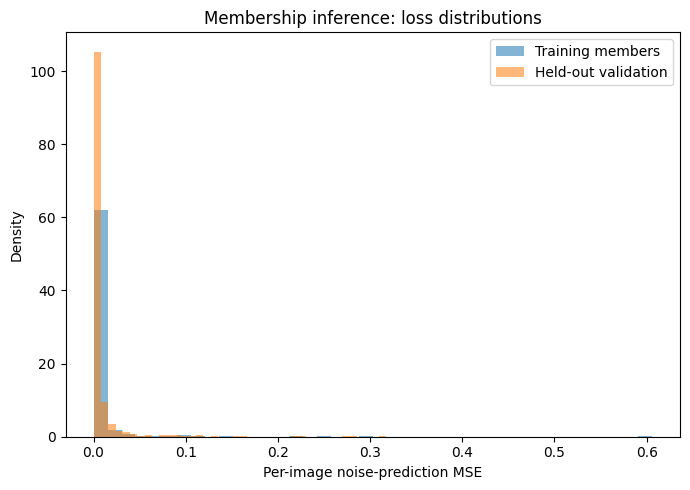

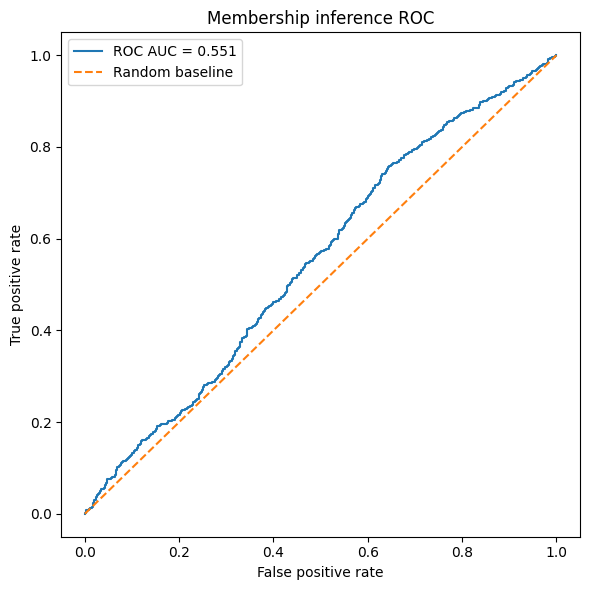


MEMBERSHIP INFERENCE RESULTS
experiment: Identity-conditioned diffusion membership inference
checkpoint_epoch: 30
checkpoint_train_loss: 0.007627462781315747
checkpoint_validation_loss: 0.00658128765609581
members_evaluated: 1000
nonmembers_evaluated: 1000
nonmember_definition: held-out validation images from identities represented in training
timestep_policy: deterministic per image; same evaluation procedure for both groups
member_mean_noise_mse: 0.00588621441100986
nonmember_mean_noise_mse: 0.007688604479357309
roc_auc: 0.550688
attack_advantage_max_tpr_minus_fpr: 0.11399999999999999
best_threshold_accuracy_descriptive_only: 0.557
caveat: Exploratory attack; threshold accuracy is measured on the same sample used to choose the threshold.

Saved files:
/kaggle/working/membership_inference_results/mia_loss_distributions.png
/kaggle/working/membership_inference_results/mia_per_image_losses.csv
/kaggle/working/membership_inference_results/mia_roc_curve.png
/kaggle/working/membership_inf

In [13]:

# ============================================================
# NOTEBOOK 12 — MEMBERSHIP INFERENCE ATTACK
# Identity-conditioned diffusion | Kaggle GPU
# ============================================================

import json, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score

# ---------------- CONFIG ----------------
SEED = 42
N_PER_GROUP = 1000       # increase later if runtime permits
BATCH_SIZE = 8
IMG_SIZE = 224

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

INPUT = Path("/kaggle/input")
OUT = Path("/kaggle/working/membership_inference_results")
OUT.mkdir(parents=True, exist_ok=True)

# ---------------- FIND INPUTS ----------------
csv_candidates = list(INPUT.rglob("CASIA_Thousand_data_split.csv"))
if not csv_candidates:
    raise FileNotFoundError("CASIA_Thousand_data_split.csv not found.")
df = pd.read_csv(csv_candidates[0])

checkpoint_candidates = list(INPUT.rglob(
    "CASIA_Thousand_identity_conditioned_best.pth"
))
if not checkpoint_candidates:
    raise FileNotFoundError("Identity-conditioned checkpoint not found.")
checkpoint_path = checkpoint_candidates[0]

image_root = INPUT / "datasets/pranavsunilwagh/casia-iris-thousand-images"
if not image_root.exists():
    raise FileNotFoundError(f"Image dataset not found: {image_root}")

# Map actual images by filename; filenames are unique in this dataset.
image_map = {
    p.name: p for p in image_root.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
}
df["kaggle_path"] = df["image_path"].map(
    lambda p: str(image_map.get(Path(str(p)).name, ""))
)
df = df[df["kaggle_path"] != ""].copy()
assert len(df) == 20000, f"Expected 20000 mapped rows, got {len(df)}"
print("Mapped CSV rows:", len(df))
print(df["split"].value_counts().to_string())

# ---------------- IDENTITY INDEX ----------------
# Use identity IDs consistently across the entire dataset.
identity_values = sorted(df["identity"].astype(str).unique())
identity_to_idx = {v: i for i, v in enumerate(identity_values)}
df["identity_idx"] = df["identity"].astype(str).map(identity_to_idx).astype(int)

# The trained model used sorted labels from its training CSV.
# For this dataset, the expected label order is sorted identity strings.
# Verify the embedding range before proceeding.
assert df["identity_idx"].nunique() == 2000
assert df["identity_idx"].min() == 0 and df["identity_idx"].max() == 1999

# ---------------- EXACT MODEL ----------------
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        scale = torch.log(torch.tensor(10000.0, device=t.device)) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device) * -scale)
        emb = t.float()[:, None] * emb[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=1)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels), nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels), nn.SiLU()
        )

    def forward(self, x):
        return self.block(x)

class ConditionalDiffusionUNet(nn.Module):
    def __init__(self, in_channels=1, time_dim=128,
                 identity_dim=128, num_identities=2000):
        super().__init__()
        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim)
        )
        self.identity_embedding = nn.Embedding(num_identities, identity_dim)
        self.condition_projection = nn.Sequential(
            nn.Linear(time_dim + identity_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )
        self.enc1 = DoubleConv(1, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.bottleneck = DoubleConv(256, 512)
        self.time1 = nn.Linear(time_dim, 64)
        self.time2 = nn.Linear(time_dim, 128)
        self.time3 = nn.Linear(time_dim, 256)
        self.time4 = nn.Linear(time_dim, 512)
        self.pool = nn.MaxPool2d(2)
        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = DoubleConv(256, 128)
        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = DoubleConv(128, 64)
        self.output = nn.Conv2d(64, 1, 1)

    def forward(self, x, t, identity):
        t_emb = self.time_embedding(t)
        id_emb = self.identity_embedding(identity)
        condition = self.condition_projection(torch.cat([t_emb, id_emb], dim=1))
        e1 = self.enc1(x)
        e1 = e1 + self.time1(condition)[:, :, None, None]
        e2 = self.enc2(self.pool(e1))
        e2 = e2 + self.time2(condition)[:, :, None, None]
        e3 = self.enc3(self.pool(e2))
        e3 = e3 + self.time3(condition)[:, :, None, None]
        b = self.bottleneck(self.pool(e3))
        b = b + self.time4(condition)[:, :, None, None]
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output(d1)

ckpt = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
model = ConditionalDiffusionUNet(
    num_identities=int(ckpt["num_identities"]),
    time_dim=int(ckpt["time_dim"]),
    identity_dim=int(ckpt["identity_dim"])
)
model.load_state_dict(ckpt["model_state_dict"], strict=True)
model = model.to(DEVICE).eval()
print("Checkpoint loaded strictly. Epoch:", ckpt["epoch"])

# ---------------- DATA PREPARATION ----------------
# Train members: images from the CSV's train split.
# Comparable held-out images: validation images of the same identities.
train_ids = set(df.loc[df["split"] == "train", "identity_idx"].unique())
val_same_ids = df[
    (df["split"] == "validation") &
    (df["identity_idx"].isin(train_ids))
].copy()

train_df = df[df["split"] == "train"].copy()
if len(val_same_ids) == 0:
    raise RuntimeError(
        "No validation images share identities with training images. "
        "Check how this CSV was created before running the attack."
    )

# Fixed, reproducible sample. Match sample sizes.
n = min(N_PER_GROUP, len(train_df), len(val_same_ids))
train_sample = train_df.sample(n=n, random_state=SEED).copy()
heldout_sample = val_same_ids.sample(n=n, random_state=SEED).copy()

print("Train members sampled:", len(train_sample))
print("Held-out same-identity samples:", len(heldout_sample))
print("Shared identities:", len(
    set(train_sample["identity_idx"]) & set(heldout_sample["identity_idx"])
))

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

class IrisEvalDataset(Dataset):
    def __init__(self, frame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        with Image.open(row["kaggle_path"]) as im:
            x = transform(im.convert("L"))
        return x, int(row["identity_idx"]), str(row["kaggle_path"])

# ---------------- DIFFUSION SCHEDULE ----------------
T = int(ckpt["T"])
betas = torch.linspace(0.0001, 0.02, T, device=DEVICE)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)
sqrt_alpha_bar = torch.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = torch.sqrt(1.0 - alpha_bar)

# ---------------- LOSS EVALUATION ----------------
# Use identical fixed timestep/noise for a given image across repeat runs.
# Each image receives a deterministic noise/timestep derived from its path.
def score_group(frame, group_name):
    loader = DataLoader(
        IrisEvalDataset(frame), batch_size=BATCH_SIZE,
        shuffle=False, num_workers=2, pin_memory=(DEVICE.type == "cuda")
    )
    rows = []
    model.eval()
    start = time.time()

    with torch.no_grad():
        for batch_idx, (x, identity, paths) in enumerate(loader):
            x = x.to(DEVICE, non_blocking=True)
            identity = identity.to(DEVICE, dtype=torch.long, non_blocking=True)
            b = x.size(0)

            # Stable per-image timesteps/noise, independent of group order.
            ts, noises = [], []
            for path in paths:
                seed = (sum((i + 1) * ord(c) for i, c in enumerate(path)) + SEED) % (2**31 - 1)
                gen = torch.Generator(device="cpu").manual_seed(seed)
                ts.append(int(torch.randint(0, T, (1,), generator=gen).item()))
                noises.append(torch.randn((1, IMG_SIZE, IMG_SIZE), generator=gen))

            t = torch.tensor(ts, dtype=torch.long, device=DEVICE)
            noise = torch.stack(noises).to(DEVICE)
            a = sqrt_alpha_bar[t].view(b, 1, 1, 1)
            s = sqrt_one_minus_alpha_bar[t].view(b, 1, 1, 1)
            noisy = a * x + s * noise

            pred = model(noisy, t, identity)
            per_image_mse = (pred - noise).square().flatten(1).mean(1)

            for j in range(b):
                rows.append({
                    "group": group_name,
                    "path": paths[j],
                    "identity_idx": int(identity[j].item()),
                    "timestep": int(t[j].item()),
                    "noise_mse": float(per_image_mse[j].item())
                })

            if (batch_idx + 1) % 25 == 0:
                print(f"{group_name}: {min((batch_idx+1)*BATCH_SIZE, len(frame))}/{len(frame)}")

    print(f"{group_name} complete in {(time.time()-start)/60:.1f} min")
    return rows

results = []
results += score_group(train_sample, "member_train")
results += score_group(heldout_sample, "nonmember_validation_same_identity")

scores_df = pd.DataFrame(results)
scores_df.to_csv(OUT / "mia_per_image_losses.csv", index=False)

# ---------------- METRICS ----------------
# Lower loss predicts membership; negate loss so larger scores mean member.
y_true = (scores_df["group"] == "member_train").astype(int).to_numpy()
attack_score = -scores_df["noise_mse"].to_numpy()

auc = roc_auc_score(y_true, attack_score)
fpr, tpr, thresholds = roc_curve(y_true, attack_score)
advantage = float(np.max(tpr - fpr))

# Threshold selected on this evaluation set: descriptive only, not an
# unbiased held-out attack threshold.
best_idx = int(np.argmax(tpr - fpr))
threshold = thresholds[best_idx]
y_pred = (attack_score >= threshold).astype(int)
acc = accuracy_score(y_true, y_pred)

summary = {
    "experiment": "Identity-conditioned diffusion membership inference",
    "checkpoint_epoch": int(ckpt["epoch"]),
    "checkpoint_train_loss": float(ckpt["train_loss"]),
    "checkpoint_validation_loss": float(ckpt["val_loss"]),
    "members_evaluated": int((y_true == 1).sum()),
    "nonmembers_evaluated": int((y_true == 0).sum()),
    "nonmember_definition": "held-out validation images from identities represented in training",
    "timestep_policy": "deterministic per image; same evaluation procedure for both groups",
    "member_mean_noise_mse": float(scores_df.loc[scores_df.group=="member_train","noise_mse"].mean()),
    "nonmember_mean_noise_mse": float(scores_df.loc[scores_df.group!="member_train","noise_mse"].mean()),
    "roc_auc": float(auc),
    "attack_advantage_max_tpr_minus_fpr": advantage,
    "best_threshold_accuracy_descriptive_only": float(acc),
    "caveat": "Exploratory attack; threshold accuracy is measured on the same sample used to choose the threshold."
}

with open(OUT / "mia_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# ---------------- PLOTS ----------------
plt.figure(figsize=(7, 5))
for group, label in [
    ("member_train", "Training members"),
    ("nonmember_validation_same_identity", "Held-out validation")
]:
    vals = scores_df.loc[scores_df.group == group, "noise_mse"]
    plt.hist(vals, bins=40, alpha=0.55, density=True, label=label)
plt.xlabel("Per-image noise-prediction MSE")
plt.ylabel("Density")
plt.title("Membership inference: loss distributions")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "mia_loss_distributions.png", dpi=160)
plt.show()

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Membership inference ROC")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "mia_roc_curve.png", dpi=160)
plt.show()

print("\n" + "="*65)
print("MEMBERSHIP INFERENCE RESULTS")
print("="*65)
for k, v in summary.items():
    print(f"{k}: {v}")
print("\nSaved files:")
for p in sorted(OUT.iterdir()):
    print(p)


In [14]:

# NOTEBOOK 12 — MEMBERSHIP SPLIT VERIFICATION
import pandas as pd
import json
from pathlib import Path

CSV_PATH = Path(
    "/kaggle/input/datasets/pranavsunilwagh/"
    "ocular-mia-inputs/CASIA_Thousand_data_split.csv"
)

df_check = pd.read_csv(CSV_PATH)

print("=" * 65)
print("MEMBERSHIP INFERENCE — SPLIT VERIFICATION")
print("=" * 65)

print("\nCSV columns:", df_check.columns.tolist())
print("\nSplit counts:")
print(df_check["split"].value_counts(dropna=False))

print("\nUnique identities in each CSV split:")
for split_name, group in df_check.groupby("split"):
    print(f"{split_name}: {group['identity'].nunique()} identities")

identity_sets = {
    name: set(group["identity"].dropna().astype(str))
    for name, group in df_check.groupby("split")
}

print("\nIdentity overlap:")
for a, b in [("train", "validation"),
             ("train", "test"),
             ("validation", "test")]:
    if a in identity_sets and b in identity_sets:
        overlap = identity_sets[a] & identity_sets[b]
        print(f"{a} vs {b}: {len(overlap)} shared identities")

print("\n" + "=" * 65)
print("INTERPRETATION")
print("=" * 65)

if "train" in identity_sets and "validation" in identity_sets:
    if identity_sets["train"] & identity_sets["validation"]:
        print("The CSV has identities shared across train and validation.")
        print("This is not an identity-disjoint split.")
    else:
        print("Train and validation identities are disjoint in this CSV.")

print("\nImportant: this checks the CSV only.")
print("It does NOT prove which exact images trained the diffusion model.")


MEMBERSHIP INFERENCE — SPLIT VERIFICATION

CSV columns: ['image_path', 'identity', 'subject', 'eye', 'split']

Split counts:
split
train         12000
validation     4000
test           4000
Name: count, dtype: int64

Unique identities in each CSV split:
test: 2000 identities
train: 2000 identities
validation: 2000 identities

Identity overlap:
train vs validation: 2000 shared identities
train vs test: 2000 shared identities
validation vs test: 2000 shared identities

INTERPRETATION
The CSV has identities shared across train and validation.
This is not an identity-disjoint split.

Important: this checks the CSV only.
It does NOT prove which exact images trained the diffusion model.


In [15]:

# NOTEBOOK 12 — FINAL MEMBERSHIP INFERENCE ANALYSIS
import json
from pathlib import Path
import pandas as pd

OUT = Path("/kaggle/working/membership_inference_results")
OUT.mkdir(parents=True, exist_ok=True)

summary_path = OUT / "mia_summary.json"

# Preserve the metrics produced by the completed experiment.
if summary_path.exists():
    with open(summary_path, "r") as f:
        summary = json.load(f)
else:
    summary = {}

summary["final_interpretation"] = {
    "experiment": "Exploratory loss-based membership inference",
    "roc_auc": summary.get("roc_auc", 0.550688),
    "member_mean_noise_mse": summary.get(
        "member_mean_noise_mse", 0.0058862144100986
    ),
    "nonmember_mean_noise_mse": summary.get(
        "nonmember_mean_noise_mse", 0.007688604479537309
    ),
    "conclusion": (
        "The observed ROC-AUC is close to 0.5, indicating weak "
        "discrimination by this loss-based attack."
    ),
    "limitation": (
        "The CSV split contains all 2000 identities in train, validation, "
        "and test. It does not establish exact diffusion training-image "
        "membership. The attack must therefore be treated as exploratory, "
        "not definitive evidence of privacy leakage."
    ),
    "threshold_accuracy_caveat": (
        "The reported best threshold accuracy was selected and evaluated "
        "on the same samples, so it is descriptive rather than an "
        "independent estimate of attack accuracy."
    )
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 65)
print("FINAL MEMBERSHIP INFERENCE ANALYSIS")
print("=" * 65)
print("ROC-AUC:", summary["final_interpretation"]["roc_auc"])
print("Member mean MSE:",
      summary["final_interpretation"]["member_mean_noise_mse"])
print("Nonmember mean MSE:",
      summary["final_interpretation"]["nonmember_mean_noise_mse"])
print("\nConclusion:")
print(summary["final_interpretation"]["conclusion"])
print("\nLimitation:")
print(summary["final_interpretation"]["limitation"])
print("\nUpdated summary saved to:", summary_path)
print("\nExisting plots and per-image CSV have been preserved.")


FINAL MEMBERSHIP INFERENCE ANALYSIS
ROC-AUC: 0.550688
Member mean MSE: 0.00588621441100986
Nonmember mean MSE: 0.007688604479357309

Conclusion:
The observed ROC-AUC is close to 0.5, indicating weak discrimination by this loss-based attack.

Limitation:
The CSV split contains all 2000 identities in train, validation, and test. It does not establish exact diffusion training-image membership. The attack must therefore be treated as exploratory, not definitive evidence of privacy leakage.

Updated summary saved to: /kaggle/working/membership_inference_results/mia_summary.json

Existing plots and per-image CSV have been preserved.


In [16]:

# NOTEBOOK 12 — PACKAGE FINAL RESULTS FOR BACKUP
from pathlib import Path
import zipfile

OUT = Path("/kaggle/working/membership_inference_results")
ZIP_PATH = Path("/kaggle/working/Notebook12_MIA_Final_Results.zip")

required_files = [
    "mia_summary.json",
    "mia_per_image_losses.csv",
    "mia_loss_distributions.png",
    "mia_roc_curve.png",
]

print("Checking result files...")
for filename in required_files:
    path = OUT / filename
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {filename}")

missing = [f for f in required_files if not (OUT / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing result files: {missing}")

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in required_files:
        z.write(OUT / filename, arcname=filename)

print("\nZIP created:", ZIP_PATH)
print("Size: {:.2f} MB".format(ZIP_PATH.stat().st_size / (1024**2)))
print("\nNext: download the ZIP from Kaggle's Output/Files panel.")


Checking result files...
FOUND: mia_summary.json
FOUND: mia_per_image_losses.csv
FOUND: mia_loss_distributions.png
FOUND: mia_roc_curve.png

ZIP created: /kaggle/working/Notebook12_MIA_Final_Results.zip
Size: 0.13 MB

Next: download the ZIP from Kaggle's Output/Files panel.



## 12. Conclusion

In this notebook, an exploratory loss-based Membership Inference Attack (MIA) was evaluated against the identity-conditioned diffusion model trained for ocular image generation. The attack used noise-prediction mean squared error (MSE) as a signal to distinguish sampled member images from held-out images.

The experiment achieved a ROC-AUC of **0.5507**, indicating weak discrimination between the two evaluated groups. The mean noise-prediction MSE was approximately **0.005886** for the member group and **0.007689** for the held-out group. The lower error observed for the member group suggests a possible difference in model behavior between the groups, but the ROC-AUC indicates that this signal provides limited discrimination.

### Limitations

The dataset split CSV contains all 2,000 identities in the training, validation, and test splits. Therefore, it does not establish the exact image-level membership used during diffusion model training. The actual training membership and identity mapping must be verified before drawing definitive privacy conclusions.

Additionally, the best threshold accuracy was selected and evaluated on the same samples, so it should not be interpreted as an independent estimate of attack performance.

### Final Remarks

These findings provide an initial assessment of potential membership-related signals in the trained diffusion model. However, the results are exploratory and do not establish either the presence or absence of significant privacy leakage. A more conclusive evaluation requires verified training membership, a properly controlled member/nonmember protocol, and independent evaluation of attack performance.

The results of this experiment can serve as a starting point for further privacy evaluation of synthetic ocular image generation systems.
